## Домашнее задание 1 (10 баллов)

В рамках этой лабораторной работы вам предстоит освоить на практике этапы первичной обработки информации и ее последующего исследовательского анализа.Вы примените инструменты numpy, pandas, matplotlib и seaborn для решения проблемы, максимально приближенной к рабочим условиям.
Суть задачи — построение модели кредитного скоринга для определения надежности заявителя. Датасет содержит профили 1000 человек, описанных 20 параметрами, с итоговой маркировкой их кредитоспособности. Вам нужно будет привести данные в порядок, проанализировать их (включая создание графиков) и на основе выявленных закономерностей предложить простой метод расчета скорингового балла. Пояснения к полям данных доступны здесь: 

https://www.rdocumentation.org/packages/evtree/versions/1.0-8/topics/GermanCredit

Любая созданная вами диаграмма должна быть аккуратно подписана (название, оси) и сопровождаться небольшим выводом, поясняющим, что на ней показано.

*Функции, которые могут пригодиться при оформлении графиков: `.show()`, `.title()`, `.xlabel()`, `.ylabel()`*

In [1]:
import pandas as pd
from pathlib import Path

data_dir = Path('./data/')

### Задание 1 (0.0 балла)

Прочитайте средствами pandas файл с данными(файл 'german_credit.csv'). Выведите базовое представление таблицы (первые 5 и последние 5 строк, размер).

In [2]:
# your code here
data = pd.read_csv(
    filepath_or_buffer=data_dir / 'german_credit.csv'
)

#### Первые 5 строк

In [3]:
data.head()

,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,no checking account,18,all credits at this bank paid back duly,car (used),1049,unknown/no savings account,< 1 yr,< 20,female : non-single or male : single,none,...,car or other,21,none,for free,1,skilled employee/official,0 to 2,no,no,good
1,no checking account,9,all credits at this bank paid back duly,others,2799,unknown/no savings account,1 <= ... < 4 yrs,25 <= ... < 35,male : married/widowed,none,...,unknown / no property,36,none,for free,2-3,skilled employee/official,3 or more,no,no,good
2,... < 0 DM,12,no credits taken/all credits paid back duly,retraining,841,... < 100 DM,4 <= ... < 7 yrs,25 <= ... < 35,female : non-single or male : single,none,...,unknown / no property,23,none,for free,1,unskilled - resident,0 to 2,no,no,good
3,no checking account,12,all credits at this bank paid back duly,others,2122,unknown/no savings account,1 <= ... < 4 yrs,20 <= ... < 25,male : married/widowed,none,...,unknown / no property,39,none,for free,2-3,unskilled - resident,3 or more,no,yes,good
4,no checking account,12,all credits at this bank paid back duly,others,2171,unknown/no savings account,1 <= ... < 4 yrs,< 20,male : married/widowed,none,...,car or other,38,bank,rent,2-3,unskilled - resident,0 to 2,no,yes,good


#### Последние 5 строк

In [4]:
data.tail()

,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
995,no checking account,24,no credits taken/all credits paid back duly,furniture/equipment,1987,unknown/no savings account,1 <= ... < 4 yrs,25 <= ... < 35,male : married/widowed,none,...,unknown / no property,21,none,for free,1,unskilled - resident,3 or more,no,no,bad
996,no checking account,24,no credits taken/all credits paid back duly,others,2303,unknown/no savings account,>= 7 yrs,< 20,male : married/widowed,co-applicant,...,unknown / no property,45,none,rent,1,skilled employee/official,0 to 2,no,no,bad
997,... >= 200 DM / salary for at least 1 year,21,all credits at this bank paid back duly,others,12680,... >= 1000 DM,>= 7 yrs,< 20,male : married/widowed,none,...,real estate,30,none,own,1,manager/self-empl./highly qualif. employee,0 to 2,yes (under customer name),no,bad
998,... < 0 DM,12,no credits taken/all credits paid back duly,furniture/equipment,6468,... >= 1000 DM,unemployed,25 <= ... < 35,male : married/widowed,none,...,real estate,52,none,rent,1,manager/self-empl./highly qualif. employee,0 to 2,yes (under customer name),no,bad
999,no checking account,30,no credits taken/all credits paid back duly,car (used),6350,... >= 1000 DM,>= 7 yrs,< 20,male : married/widowed,none,...,car or other,31,none,rent,1,skilled employee/official,0 to 2,no,no,bad


#### Размер датасета

In [5]:
data.shape

(1000, 21)

**Вывод:**
- 1000 записей и 21 признак

### Задание 2 (0.5 балла)

Определите, есть ли пропуски в данных. Разделите признаки на количественные, бинарные, порядковые и категориальные.

In [6]:
print(f'Всего пропусков в датасете: {data.isna().sum().sum()}')

data.isna().sum().to_frame(name='Количество')

Всего пропусков в датасете: 0


,Количество
status,0
duration,0
credit_history,0
purpose,0
amount,0
savings,0
employment_duration,0
installment_rate,0
personal_status_sex,0
other_debtors,0


| # | Признак | Тип |
|---|---------|-----|
| 0 | status | **Категориальный** (номинальный) |
| 1 | duration | **Количественный** |
| 2 | credit_history | **Категориальный** (номинальный) |
| 3 | purpose | **Категориальный** (номинальный) |
| 4 | amount | **Количественный** |
| 5 | savings | **Категориальный** (номинальный) |
| 6 | employment_duration | **Категориальный** (номинальный) |
| 7 | installment_rate | **Категориальный** (номинальный) |
| 8 | personal_status_sex | **Категориальный** (номинальный) |
| 9 | other_debtors | **Категориальный** (номинальный) |
| 10 | present_residence | **Категориальный** (номинальный) |
| 11 | property | **Категориальный** (номинальный) |
| 12 | age | **Количественный** |
| 13 | other_installment_pl | **Категориальный** (номинальный) |
| 14 | housing | **Категориальный** (номинальный) |
| 15 | number_credits | **Категориальный** (порядковый) |
| 16 | job | **Категориальный** (номинальный) |
| 17 | people_liable | **Бинарный** |
| 18 | telephone | **Бинарный** |
| 19 | foreign_worker | **Бинарный** |
| 20 | credit_risk | **Бинарный** |

### Задание 3 (0.5 балла)

In [7]:
data.number_credits.unique()

<StringArray>
['1', '2-3', '4-5', '>= 6']
Length: 4, dtype: str

Выведите среднюю сумму кредита (колонка amount) в каждой категории (колонка purpose), воспользовавшись методом groupby.

In [8]:
data.groupby(
    by='purpose'
).amount.mean().to_frame(name='Среднее значение')

,Среднее значение
purpose,
business,8209.333333
car (new),5370.223301
car (used),3066.983425
domestic appliances,2728.090909
furniture/equipment,2487.685714
others,3062.948718
radio/television,1498.000000
repairs,3180.400000
retraining,4158.041237


### Задание 4 (0.5 балла)


Какой процент клиентов моложе 30 лет (колонка age) снимает жилье (колонка housing)? А какой процент клиентов старше 40 лет снимает жилье?

In [9]:
print(f'Клиенты моложе 30 лет снимающие жилье: {data.loc[(data.age < 30) & (data.housing == 'rent'), 'age'].count() / data.loc[data.age < 30, 'age'].count()}')

Клиенты моложе 30 лет снимающие жилье: 0.6666666666666666


### Задание 5 (0.5 балла)

 У скольких иностранцев (foreign_worker) число кредитов (number_credits) больше 3?

In [10]:
print(f'Количество иностранцев у которых больше трех кредитов: {data.loc[(data.foreign_worker == 'yes') & (data.number_credits.isin(['4-5', '>= 6'])), 'age'].count()}')

Количество иностранцев у которых больше трех кредитов: 1


In [11]:
data.number_credits.unique()

<StringArray>
['1', '2-3', '4-5', '>= 6']
Length: 4, dtype: str

### Задание 6 (1 балл)

In [12]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

Используя numpy и matplotlib, начнём с тренировки: постройте график функций $sin(x)$ и $cos(x)$ от $-\pi$ до $\pi$ из 100 точек c легендой и сеткой. Используйте для линий разные цвета, одна из них пусть будет пунктирной. Результат в этом и следующих заданиях на построение графиков должен получиться примерно как на картинке. Содержание подписей не должно обязательно совпадать, однако осмысленные подписи должны присутствовать на графиках.

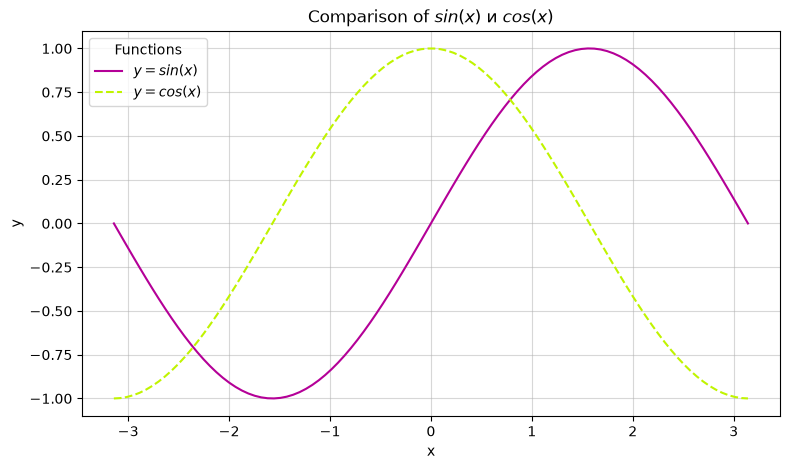

In [47]:
_, ax = plt.subplots(figsize=(9, 5))

x = np.linspace(
    start=-np.pi,
    stop=np.pi,
    num=100
)

ax.plot(x, np.sin(x), label='$y=sin(x)$', color='#B40097', linestyle='-')
ax.plot(x, np.cos(x), label='$y=cos(x)$', color='#C0F400', linestyle='--')

ax.set(
    xlabel='x',
    ylabel='y',
    title='Comparison of $sin(x)$ и $cos(x)$',
)

ax.legend(loc='upper left', title='Functions')
ax.grid(alpha=0.5)

plt.show()

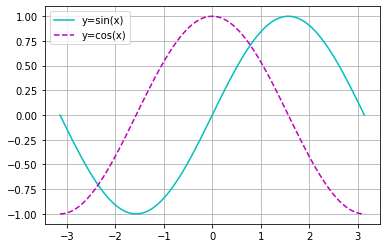

In [8]:
# your code here

### Задание 7 (1 балл)

Рассмотрим сравнительное количество положительных и отрицательных кейсов в зависимости от размера текущего счёта. Постройте зеркальные горизонтальные гистограммы.

In [50]:
good_data = data.loc[data.credit_risk == 'good', 'status'].value_counts().to_frame(name='count_good')
bad_data = data.loc[data.credit_risk == 'bad', 'status'].value_counts().to_frame(name='count_bad')
status_data = pd.concat([good_data, bad_data], axis=1)
status_data

,count_good,count_bad
status,,
... >= 200 DM / salary for at least 1 year,348,46
... < 0 DM,164,105
no checking account,139,135
0<= ... < 200 DM,49,14


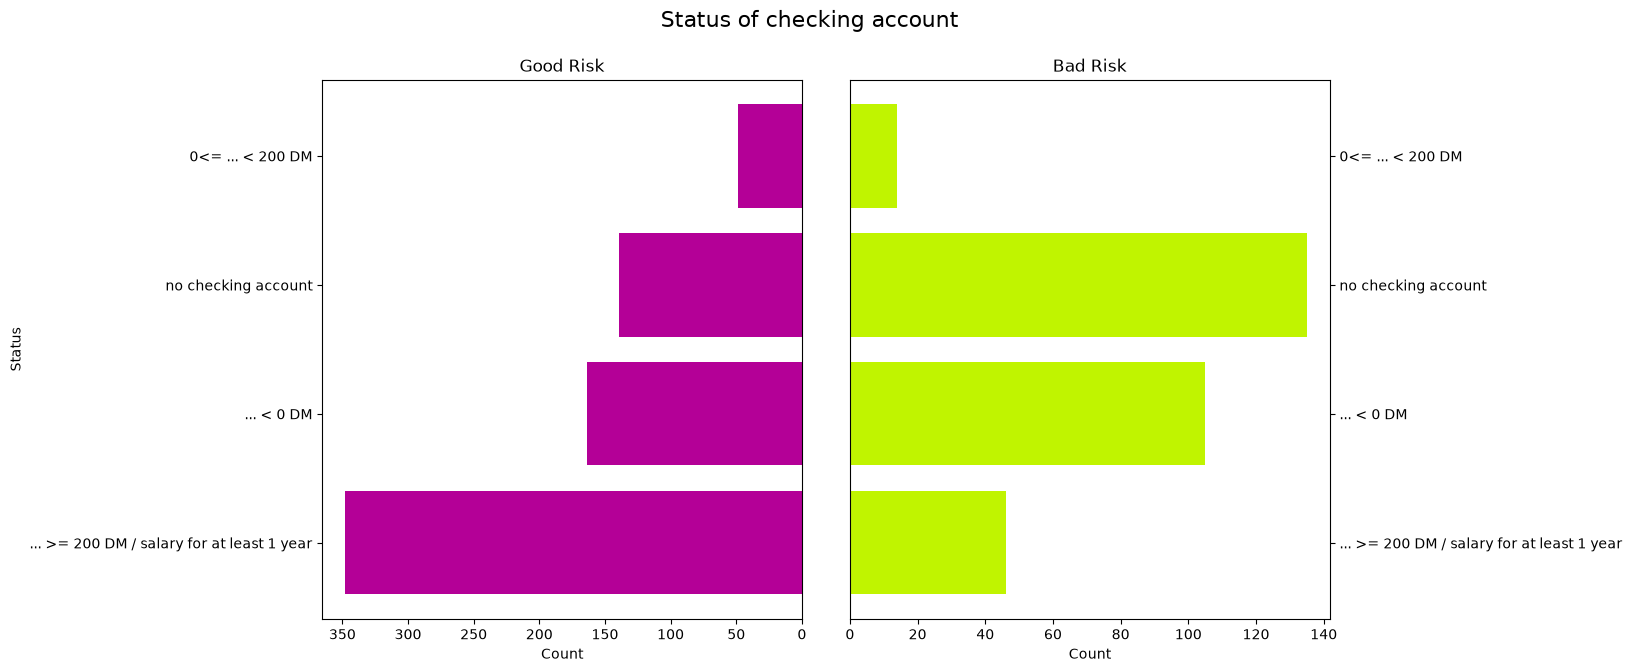

In [51]:
from matplotlib.axes import Axes
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, sharey=False, figsize=(13, 7))

assert isinstance(ax1, Axes)
assert isinstance(ax2, Axes)

ax1.barh(status_data.index.values, status_data.count_good, color='#B40097')
ax2.barh(status_data.index.values, status_data.count_bad, color='#C0F400')

ax1.set(
    xlabel='Count',
    ylabel='Status',
    title='Good Risk'
)
ax1.invert_xaxis()

ax2.set(
    xlabel='Count',
    title='Bad Risk'
)
ax2.yaxis.tick_right()

fig.subplots_adjust(wspace=0.1)
fig.suptitle(t='Status of checking account', fontsize=16)
plt.show()

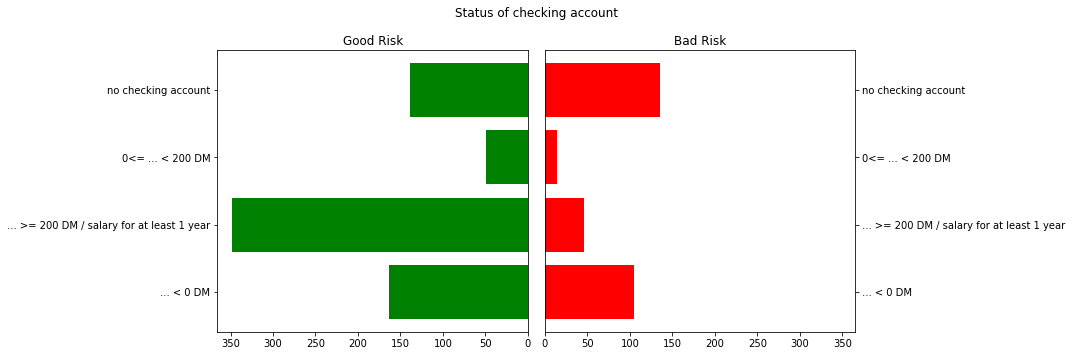

In [9]:
# your code here

### Задание 8  (0.5 балла)

In [54]:
import seaborn as sns

good_data = data.loc[data.credit_risk == 'good', 'savings'].value_counts().to_frame(name='count_good')
bad_data = data.loc[data.credit_risk == 'bad', 'savings'].value_counts().to_frame(name='count_bad')
saving_data = pd.concat([good_data, bad_data], axis=1)
saving_data = saving_data.reset_index()
saving_data

,savings,count_good,count_bad
0,unknown/no savings account,386,217
1,... >= 1000 DM,151,32
2,... < 100 DM,69,34
3,100 <= ... < 500 DM,52,11
4,500 <= ... < 1000 DM,42,6


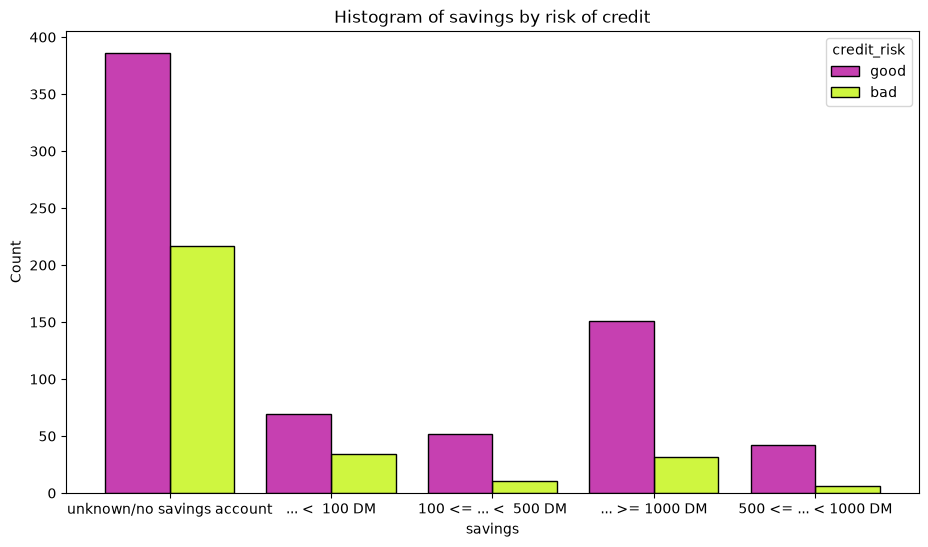

In [96]:
fig, ax = plt.subplots(figsize=(11, 6))

# sns.barplot(data=saving_data, x='savings', y='count_good', ax=ax, color='#B40097', label='good', dodge=False)
# sns.barplot(data=saving_data, x='savings', y='count_bad', ax=ax, color='#C0F400', label='bad', dodge=False)

# melted_data = pd.melt(saving_data, id_vars=['savings'], value_vars=['count_good', 'count_bad'], var_name='type', value_name='count')

sns.histplot(
    data=data,
    x='savings',
    hue='credit_risk', 
    palette=['#B40097', '#C0F400'], 
    multiple='dodge', 
    legend=True, 
    shrink=0.8,
    ax=ax
)
ax.set_title(label='Histogram of savings by risk of credit')

plt.show()

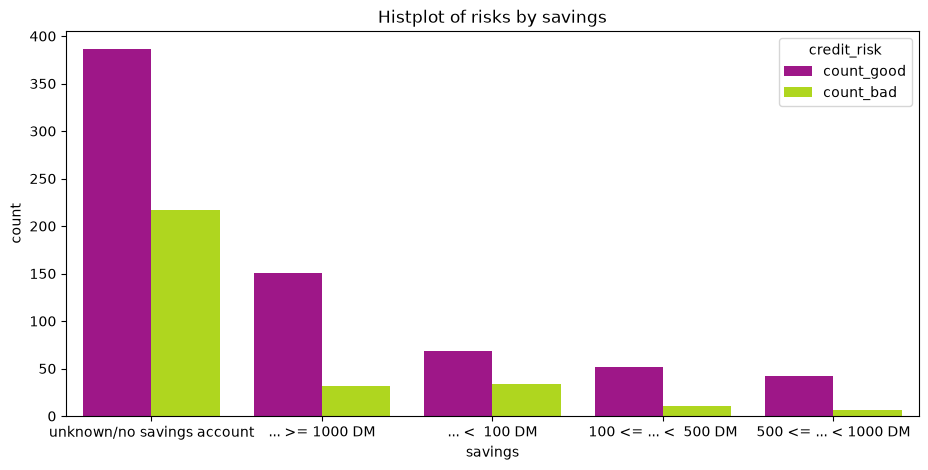

In [72]:
fig, ax = plt.subplots(figsize=(11, 5))

# sns.barplot(data=saving_data, x='savings', y='count_good', ax=ax, color='#B40097', label='good', dodge=False)
# sns.barplot(data=saving_data, x='savings', y='count_bad', ax=ax, color='#C0F400', label='bad', dodge=False)

melted_data = pd.melt(saving_data, id_vars=['savings'], value_vars=['count_good', 'count_bad'], var_name='type', value_name='count')

sns.barplot(melted_data, x='savings', y='count', hue='type', palette=['#B40097', '#C0F400'])

ax.set(
    ylabel='count',
    title='Histplot of risks by savings'
)
ax.legend(title='credit_risk')

plt.show()

In [80]:
melted_data

,savings,type,count
0,unknown/no savings account,count_good,386
1,... >= 1000 DM,count_good,151
2,... < 100 DM,count_good,69
3,100 <= ... < 500 DM,count_good,52
4,500 <= ... < 1000 DM,count_good,42
5,unknown/no savings account,count_bad,217
6,... >= 1000 DM,count_bad,32
7,... < 100 DM,count_bad,34
8,100 <= ... < 500 DM,count_bad,11
9,500 <= ... < 1000 DM,count_bad,6


Теперь постройте гистограмму для сравнения количества положительных и отрицательных кейсов в зависимости от размера сберегательного счёта с помощью seaborn. Какой способ вам больше нравится с точки зрения трудоёмкости написания кода? А с точки зрения восприятия результата?

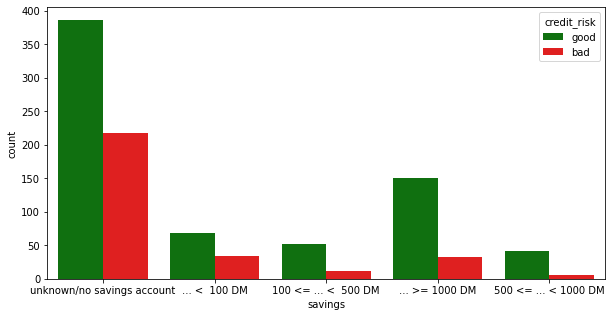

In [11]:
# your code here

### Задание 9  (1 балл)

seaborn легко позволяет добавить ещё больше информации на один график. Для каждого размера сберегательного счёта мы можем оценить не только количество положительных и отрицательных кейсов, но и их распределение по возрасту, например. Постройте подходящую для этого визуализацию.

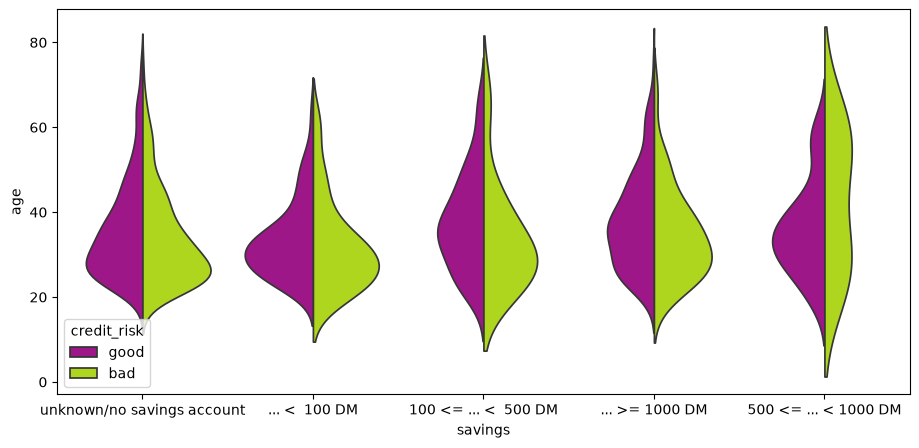

In [79]:
fig, ax = plt.subplots(figsize=(11, 5))

sns.violinplot(data=data, x='savings', y='age', hue='credit_risk', palette=['#B40097', '#C0F400'], split=True, inner=None)

ax.legend(title='credit_risk')

plt.show()

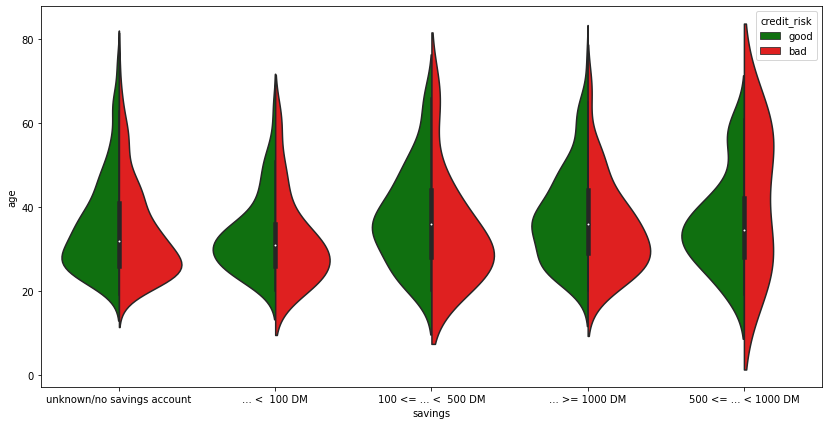

In [12]:
# your code here

### Задание 10  (0.5 балла)

Заканчивая с гистограммами, посмотрим на распределение положительных и отрицательных кейсов по возрастам, разместив их друг над другом. Добавим распределение всех взятых кредитов.

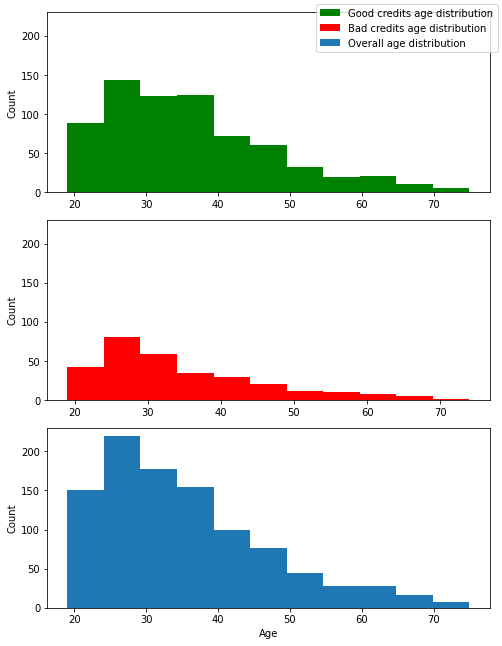

In [13]:
# your code here

### Задание 11  (0.5 балла)

Не менее полезной иногда может быть диаграмма рассеяния. Постройте такую диаграмму с продолжительностью и размерами кредитов в качестве осей. Обозначьте положительные и отрицательные кейсы разными цветами.

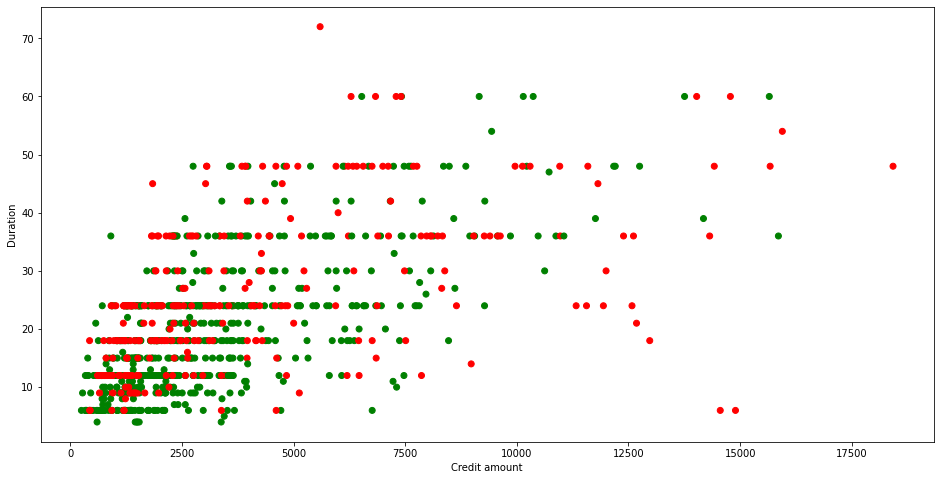

In [21]:
# your code here

### Задание 12  (1 балл)

Продвинемся глубже. Постройте 3D версию диаграммы рассеяния, добавив ось с возрастом.

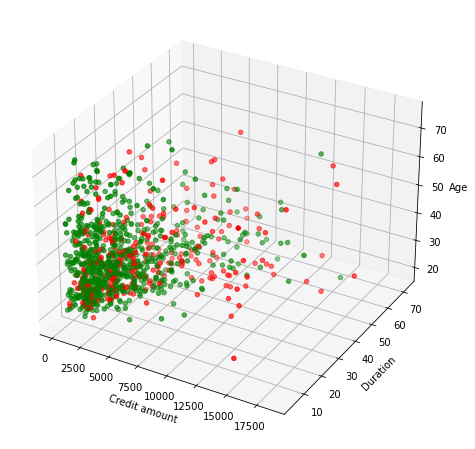

In [15]:
# your code here

### Задание 13  (0.5 балла)

Представьте все порядковые и бинарные признаки в виде числовых значений {0, ..., n - 1}, где n это количество значений признака. Избавьтесь от категориальных признаков.

In [16]:
# your code here

### Задание 14  (2 балла)

По результатам предыдущего задания у вас должна получиться таблица, в которой все признаки так или иначе представлены числовыми значениями. Попробуйте придумать на основе проведённых исследований данных какую-нибудь формулу, связывающую целевую переменную с признаками, не используя готовых инструментов машинного обучения. По желанию вы можете исключить ещё какие-то признаки, или, наоборот, сформировать новые на основе имеющихся. Возможно, вы захотите отмасштабировать большие наборы численных значений некоторых признаков с помощью интервалов. Цель: реализовать функцию, которая будет принимать на вход набор признаков для объекта выборки и возвращать прогноз целевой переменной (0 или 1). Например, вы можете просто сложить все признаки и возращать ноль, если сумма отрицательная, а в противном случае единицу. Но наверняка можно придумать лучше!
Данные уже разделены на набор для обучения, который вы можете использовать как угодно, и тестовый, на котором нужно будет проверить вашу точность. Постарайтесь достичь точности хотя бы 0.6.

In [17]:
def predict(Xtest: np.array) -> np.array:
    # your code here

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
X = data.drop('credit_risk', 1).values
y = data['credit_risk'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=10)
# Используйте X_train и y_train на ваше усмотрение
# your code here
accuracy_score(y_test, predict(X_test))